# ZG549 Assignment II - Section II: Fine-Tuning
**Group 32 | Sentiment model for the Equity Research Desk Assistant**

Fine-tunes `distilbert-base-uncased` on the **Financial PhraseBank** dataset
(`sentences_allagree`: ~2.3k financial sentences where all annotators agreed on
the positive / neutral / negative label), and compares against pretrained
**FinBERT** as the baseline.

Run on Google Colab (Runtime -> Change runtime type -> **T4 GPU**). End-to-end ~10 min.
The final cell zips the fine-tuned model; download it and unzip into the app's
`models/finetuned-sentiment/` folder.

In [1]:
!pip -q install transformers datasets accelerate scikit-learn evaluate

In [1]:
import pandas as pd
from datasets import Dataset, ClassLabel

LABELS = ["negative", "neutral", "positive"]  # label order: 0,1,2

BASE = ("https://huggingface.co/datasets/ghbacct/"
        "financial-phrasebank-all-agree-classification/resolve/"
        "refs%2Fconvert%2Fparquet/default")
df = pd.concat([
    pd.read_parquet(f"{BASE}/train/0000.parquet"),
    pd.read_parquet(f"{BASE}/test/0000.parquet"),
], ignore_index=True)
print("raw shape:", df.shape, "| columns:", df.columns.tolist())
print(df.head(2).to_dict("records"))

# normalise column names
text_col = next(c for c in df.columns if c.lower() in ("sentence", "text", "phrase"))
label_col = next(c for c in df.columns if "label" in c.lower())
df = df.rename(columns={text_col: "sentence", label_col: "label"})[["sentence", "label"]]

# normalise labels to ints 0/1/2 in LABELS order
if df["label"].dtype == object:
    df["label"] = df["label"].str.lower().map({l: i for i, l in enumerate(LABELS)})
df["label"] = df["label"].astype(int)
print("label counts:", df["label"].value_counts().to_dict())

full = Dataset.from_pandas(df, preserve_index=False)
full = full.cast_column("label", ClassLabel(names=LABELS))
ds = full.train_test_split(test_size=0.2, seed=42, stratify_by_column="label")
train_ds, test_ds = ds["train"], ds["test"]
print(train_ds, test_ds)

raw shape: (2264, 2) | columns: ['text', 'label']
[{'text': "Koff 's market share of the volume of the market was 23.4 % , Karhu 's 21.4 % .", 'label': 1}, {'text': 'The market value of one crane is some USD6m , reported the Finnish news agency STT .', 'label': 1}]
label counts: {1: 1391, 2: 570, 0: 303}


Casting the dataset:   0%|          | 0/2264 [00:00<?, ? examples/s]

Dataset({
    features: ['sentence', 'label'],
    num_rows: 1811
}) Dataset({
    features: ['sentence', 'label'],
    num_rows: 453
})


## Baseline: pretrained FinBERT on our test split
FinBERT is already finance-tuned, so it is a strong baseline; the point of this
section is to show the fine-tuning *process* and that a small generic model
(DistilBERT) reaches comparable quality after task-specific fine-tuning.

In [3]:
from transformers import pipeline
from sklearn.metrics import accuracy_score, classification_report

finbert = pipeline("text-classification", model="ProsusAI/finbert", device=0)
pred = finbert(list(test_ds["sentence"]), truncation=True, batch_size=64)
finbert_pred = [LABELS.index(p["label"].lower()) for p in pred]
finbert_acc = accuracy_score(test_ds["label"], finbert_pred)
print(f"FinBERT baseline accuracy: {finbert_acc:.4f}")
print(classification_report(test_ds["label"], finbert_pred, target_names=LABELS))

Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

FinBERT baseline accuracy: 0.9603
              precision    recall  f1-score   support

    negative       0.90      0.98      0.94        61
     neutral       0.99      0.95      0.97       278
    positive       0.93      0.97      0.95       114

    accuracy                           0.96       453
   macro avg       0.94      0.97      0.95       453
weighted avg       0.96      0.96      0.96       453



## Fine-tune DistilBERT

In [5]:
from transformers import (AutoTokenizer, AutoModelForSequenceClassification,
                          TrainingArguments, Trainer, DataCollatorWithPadding)
import numpy as np, evaluate

MODEL = "distilbert-base-uncased"
tok = AutoTokenizer.from_pretrained(MODEL)

def tokenize(batch):
    return tok(batch["sentence"], truncation=True, max_length=128)

train_tok = train_ds.map(tokenize, batched=True)
test_tok = test_ds.map(tokenize, batched=True)

model = AutoModelForSequenceClassification.from_pretrained(
    MODEL, num_labels=3,
    id2label={i: l for i, l in enumerate(LABELS)},
    label2id={l: i for i, l in enumerate(LABELS)},
)

accuracy = evaluate.load("accuracy")
def compute_metrics(eval_pred):
    logits, labels = eval_pred
    return accuracy.compute(predictions=np.argmax(logits, -1), references=labels)

args = TrainingArguments(
    output_dir="ft-out",
    num_train_epochs=3,
    per_device_train_batch_size=32,
    per_device_eval_batch_size=64,
    learning_rate=2e-5,
    eval_strategy="epoch",
    logging_steps=20,
    save_strategy="no",
    report_to="none",
    seed=42,
)

trainer = Trainer(model=model, args=args, train_dataset=train_tok,
                  eval_dataset=test_tok, processing_class=tok,
                  data_collator=DataCollatorWithPadding(tok),
                  compute_metrics=compute_metrics)
trainer.train()

Map:   0%|          | 0/1811 [00:00<?, ? examples/s]

Map:   0%|          | 0/453 [00:00<?, ? examples/s]

Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

[transformers] DistilBertForSequenceClassification LOAD REPORT from: distilbert-base-uncased
Key                     | Status     | 
------------------------+------------+-
vocab_transform.bias    | UNEXPECTED | 
vocab_transform.weight  | UNEXPECTED | 
vocab_layer_norm.bias   | UNEXPECTED | 
vocab_layer_norm.weight | UNEXPECTED | 
vocab_projector.bias    | UNEXPECTED | 
classifier.bias         | MISSING    | 
pre_classifier.bias     | MISSING    | 
pre_classifier.weight   | MISSING    | 
classifier.weight       | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.
/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py:759: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  super().__init__(load

Epoch,Training Loss,Validation Loss,Accuracy
1,0.594449,0.419172,0.845475
2,0.236852,0.189138,0.935982
3,0.141215,0.149020,0.953642


/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py:759: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  super().__init__(loader)
/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py:759: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  super().__init__(loader)


TrainOutput(global_step=171, training_loss=0.3508460277702376, metrics={'train_runtime': 1970.8223, 'train_samples_per_second': 2.757, 'train_steps_per_second': 0.087, 'total_flos': 91577484207900.0, 'train_loss': 0.3508460277702376, 'epoch': 3.0})

## Evaluate the fine-tuned model

/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py:759: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  super().__init__(loader)


FinBERT baseline accuracy   : 0.9603
Fine-tuned DistilBERT acc   : 0.9536

              precision    recall  f1-score   support

    negative       0.89      0.92      0.90        61
     neutral       0.99      0.97      0.98       278
    positive       0.90      0.93      0.91       114

    accuracy                           0.95       453
   macro avg       0.93      0.94      0.93       453
weighted avg       0.95      0.95      0.95       453



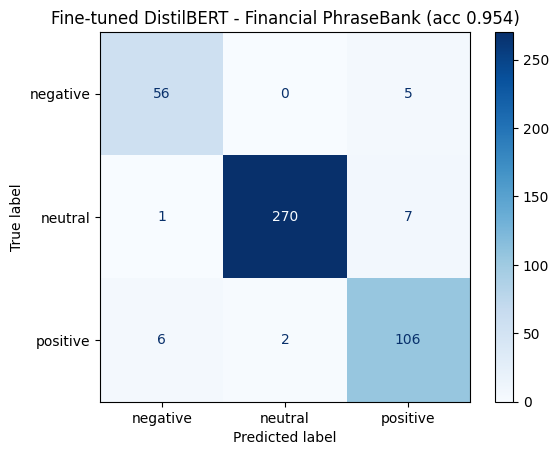

In [6]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

logits = trainer.predict(test_tok).predictions
ft_pred = logits.argmax(-1)
ft_acc = accuracy_score(test_ds["label"], ft_pred)

print(f"FinBERT baseline accuracy   : {finbert_acc:.4f}")
print(f"Fine-tuned DistilBERT acc   : {ft_acc:.4f}")
print()
print(classification_report(test_ds["label"], ft_pred, target_names=LABELS))

cm = confusion_matrix(test_ds["label"], ft_pred)
ConfusionMatrixDisplay(cm, display_labels=LABELS).plot(cmap="Blues")
plt.title(f"Fine-tuned DistilBERT - Financial PhraseBank (acc {ft_acc:.3f})")
plt.savefig("confusion_matrix.png", dpi=120, bbox_inches="tight")
plt.show()

## Save and download
Download `finetuned-sentiment.zip`, unzip into the app repo at
`models/finetuned-sentiment/`, and the Sentiment tab will offer the
fine-tuned model alongside FinBERT.

In [7]:
trainer.save_model("finetuned-sentiment")
tok.save_pretrained("finetuned-sentiment")
!zip -rq finetuned-sentiment.zip finetuned-sentiment confusion_matrix.png
from google.colab import files
files.download("finetuned-sentiment.zip")

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>